In [1]:
### image classification

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

In [3]:
#load and preprocess the CIFAR-10 dataset
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()

In [4]:
#normalize pixel value to to a range of [0,1]
train_images, test_images = train_images / 255.0, test_images / 255.0

In [5]:
#one hot encode the labels
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

In [6]:
#create a deep learning model
model= models.Sequential([
    #convoluton layers
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    #flatten the output
    layers.Flatten(),
    #fully connected layers
    layers.Dense(64, activation='relu'),
    layers.Dense(10)  # 10 classes for CIFAR-10    
])

2026-06-21 00:14:41.014013: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-06-21 00:14:41.014031: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-06-21 00:14:41.014038: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-06-21 00:14:41.014060: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-06-21 00:14:41.014071: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [7]:
#complie the model
model.compile(optimizer='adam',
              loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [8]:
#train the model
history = model.fit(train_images, train_labels, epochs=10, validation_data=(test_images, test_labels))

Epoch 1/10


2026-06-21 00:14:43.381603: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


1563/1563 [==============================] - 20s 11ms/step - loss: 1.5284 - accuracy: 0.4429 - val_loss: 1.2498 - val_accuracy: 0.5571
Epoch 2/10
1563/1563 [==============================] - 17s 11ms/step - loss: 1.1896 - accuracy: 0.5800 - val_loss: 1.1600 - val_accuracy: 0.5947
Epoch 3/10
1563/1563 [==============================] - 17s 11ms/step - loss: 1.0824 - accuracy: 0.6244 - val_loss: 1.0748 - val_accuracy: 0.6314
Epoch 4/10
1563/1563 [==============================] - 17s 11ms/step - loss: 1.1230 - accuracy: 0.6232 - val_loss: 1.2988 - val_accuracy: 0.5866
Epoch 5/10
1563/1563 [==============================] - 17s 11ms/step - loss: 1.3848 - accuracy: 0.5946 - val_loss: 1.4554 - val_accuracy: 0.5855
Epoch 6/10
1563/1563 [==============================] - 17s 11ms/step - loss: 2.1478 - accuracy: 0.5464 - val_loss: 2.9907 - val_accuracy: 0.5209
Epoch 7/10
1563/1563 [==============================] - 17s 11ms/step - loss: 4.6756 - accuracy: 0.5051 - val_loss: 8.6136 - val_accura

In [9]:
#evaluate the model
test_loss, test_acc = model.evaluate(test_images, test_labels)
print(f"Test accuracy: {test_acc}")

313/313 [==============================] - 2s 6ms/step - loss: 152.9211 - accuracy: 0.3533
Test accuracy: 0.353300005197525


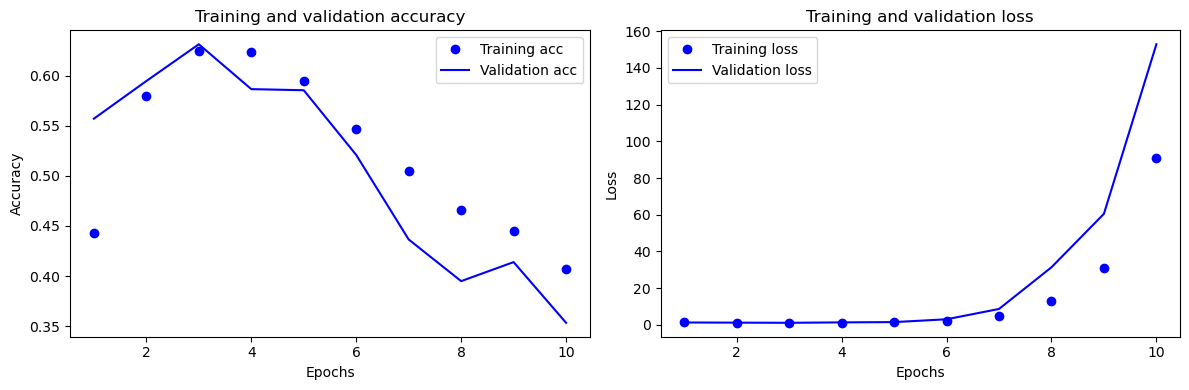

In [10]:
#visualize training history
def plot_training_history(history):
    # Extract training history metrics
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    #create plots for accuracy and loss
    epochs = range(1, len(acc) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo', label='Training acc')
    plt.plot(epochs, val_acc, 'b', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo', label='Training loss')
    plt.plot(epochs, val_loss, 'b', label='Validation loss')
    plt.title('Training and validation loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training_history(history)

313/313 [==============================] - 1s 2ms/step


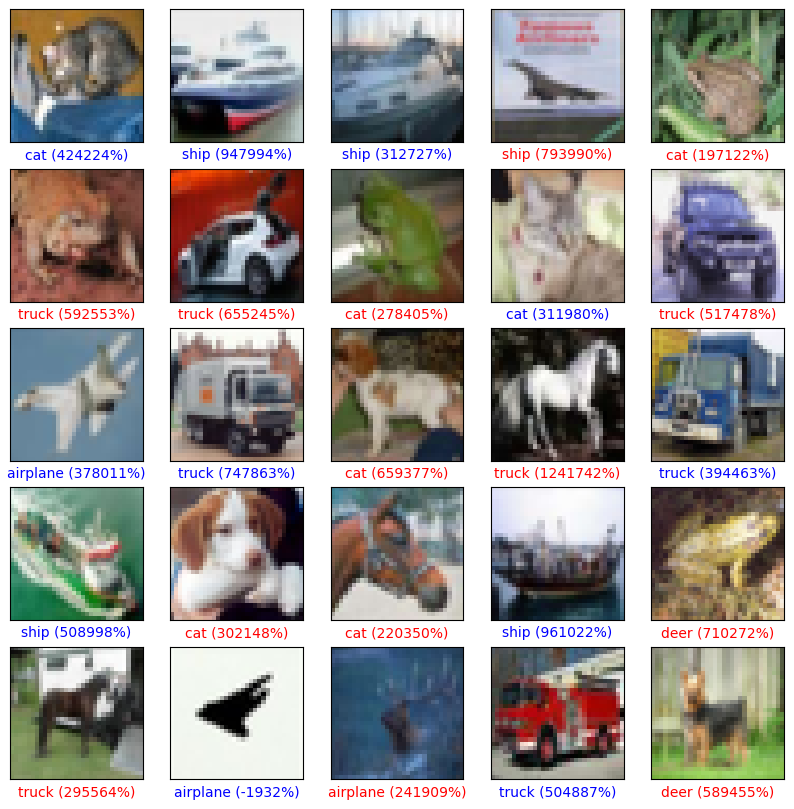

In [12]:
#visualize example predictions
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

def plot_example_predictions():
    predictions = model.predict(test_images)
    num_rows, num_cols = 5, 5
    plt.figure(figsize=(10, 10))
    for i in range(num_rows * num_cols):
        plt.subplot(num_rows, num_cols, i + 1)
        plt.grid (False)
        plt.xticks([])
        plt.yticks([])
        plt.imshow(test_images[i], cmap=plt.cm.binary)
        predicted_label = np.argmax(predictions[i])
        true_label = np.argmax(test_labels[i])
        if predicted_label == true_label:
            color = 'blue'
        else:
            color = 'red'
        plt.xlabel(f"{class_names[predicted_label]} ({100 * np.max(predictions[i]):2.0f}%)", color=color)

# call the function to plot example predictions
plot_example_predictions()